In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
!pip install plotly

In [63]:
cb = pd.read_csv('cust_bio.csv')
sp = pd.read_csv('sp.csv')
ca = pd.read_csv('cust_activity.csv')
orders = pd.read_csv('orders .csv')
cs = pd.read_csv('cust_sub.csv')


In [65]:
print(cb.shape)
print(sp.shape)
print(ca.shape)
print(orders.shape)
print(cs.shape)

(478, 3)
(6, 5)
(7500, 3)
(127, 4)
(51, 3)


In [67]:
print(cb.columns)
print(sp.columns)
print(ca.columns)
print(orders.columns)
print(cs.columns)

Index(['Cust_ID', 'City', 'Age'], dtype='object')
Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='object')
Index(['Cust_ID', 'Activity', 'Date'], dtype='object')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='object')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='object')


In [73]:
def check_null_dup(data):
    dup=data.duplicated().sum()
    nv=data.isnull().sum()
    if dup==0 and nv.sum()==0:
        print('No duplicates and no null values')
    else:
        return dup,nv
    


In [77]:
check_null_dup(ca)
check_null_dup(cb)
check_null_dup(cs)
check_null_dup(sp)
check_null_dup(orders)



No duplicates and no null values
No duplicates and no null values
No duplicates and no null values
No duplicates and no null values
No duplicates and no null values


In [79]:
import plotly.express as px

In [81]:
q2 = cb['City'].value_counts().reset_index()
q2

,City,count
0,Chennai,109
1,Delhi,106
2,Kolkata,94
3,Noida,92
4,Mumbai,77


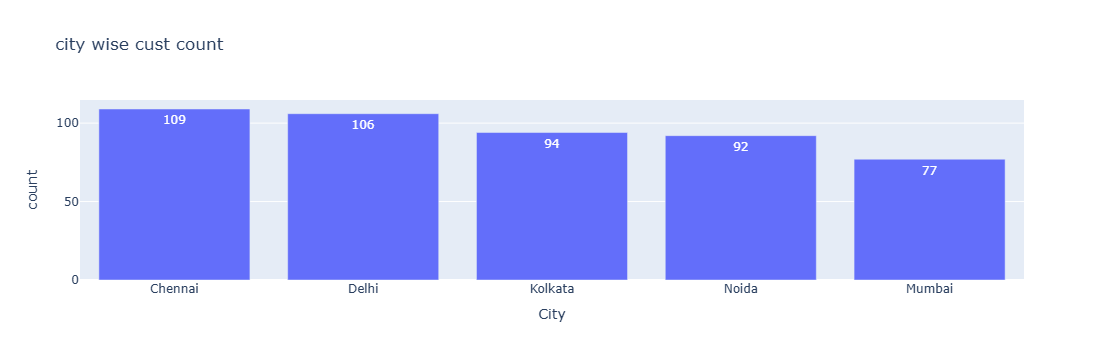

In [95]:
fig=px.bar(data_frame=q2,x ='City',y='count',text ='count',
           title='city wise cust count')
fig.show()
           

In [85]:
cb['Age_range']=pd.cut(cb['Age'],bins = [19,23,27,31,35,39])
cb['Age_range']= cb['Age_range'].astype(str)
                       

In [87]:
q3 = cb['Age_range'].value_counts().reset_index()
q3

,Age_range,count
0,"(31, 35]",116
1,"(19, 23]",112
2,"(23, 27]",95
3,"(27, 31]",93
4,"(35, 39]",62


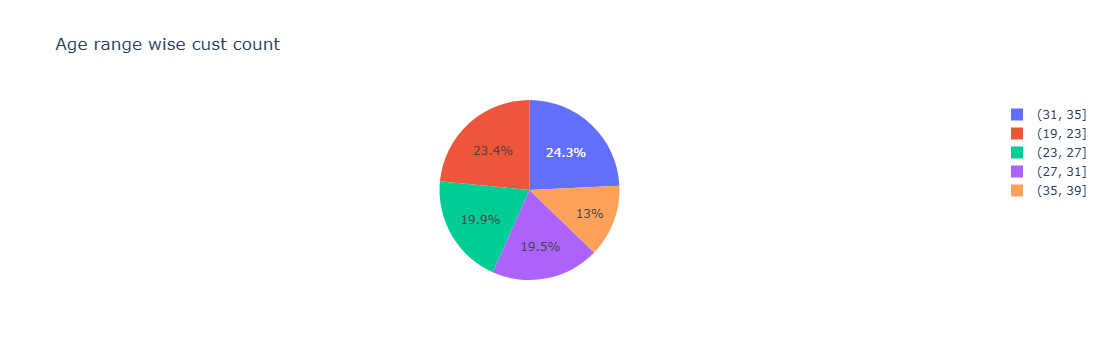

In [89]:
fig=px.pie(data_frame=q3,names ='Age_range',values='count',
           title='Age range wise cust count')
fig.show()

In [91]:
q4 = ca['Activity'].value_counts().reset_index()
q4

,Activity,count
0,Browse,6548
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


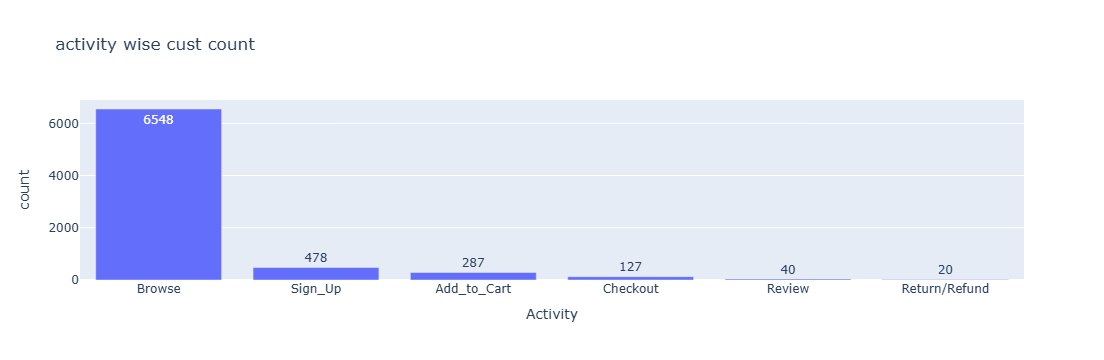

In [97]:
fig=px.bar(data_frame=q4,x ='Activity',y='count',text ='count',
           title='activity count')
fig.show()

In [127]:
ca['Date']= pd.to_datetime(ca['Date'])

In [129]:
#5) Find order month wise total amount. Represent it on line chart.
ca_cout = ca[ca['Activity'] =='Checkout']
ca_cout

,Cust_ID,Activity,Date
6,CUS_121,Checkout,2024-05-05
71,CUS_127,Checkout,2024-06-16
92,CUS_129,Checkout,2025-04-02
162,CUS_135,Checkout,2024-08-02
206,CUS_139,Checkout,2024-10-12
...,...,...,...
7110,CUS_767,Checkout,2024-05-12
7157,CUS_771,Checkout,2024-07-26
7213,CUS_776,Checkout,2025-02-07
7259,CUS_780,Checkout,2025-03-23


In [132]:
q5 = pd.merge(orders,ca_cout,on='Cust_ID')
q5.head()

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22
3,ORD_74,CUS_360,5736.31,COD,Checkout,2025-05-24
4,ORD_75,CUS_714,1592.53,Debit Card,Checkout,2024-06-19


In [140]:
q5['Order_Month'] = q5['Date'].dt.month

In [142]:
q5_ans = q5.groupby('Order_Month')['Amount'].sum().reset_index()
q5_ans

,Order_Month,Amount
0,1,27022.20
1,2,70477.42
2,3,74777.59
3,4,88080.66
4,5,60200.46
5,6,69580.07
6,7,80416.05
7,8,27227.29
8,9,34804.62
9,10,30298.38


In [148]:
cs_sp = pd.merge(cs,sp,on='Plan_Var_ID')
cs_sp.head()

,Cust_ID,Plan_Var_ID,Purchase_Date,Plan_ID,Plan_name,Price,Duration
0,CUS_626,P1_1Y,2025-05-15,P1,Silver,1200.0,1 Year
1,CUS_723,P1_1Y,2024-07-23,P1,Silver,1200.0,1 Year
2,CUS_575,P1_1Y,2024-11-14,P1,Silver,1200.0,1 Year
3,CUS_232,P2_6M,2025-04-19,P2,Gold,1440.0,6 Months
4,CUS_346,P2_1Y,2024-01-31,P2,Gold,2400.0,1 Year


In [150]:
q6 = cs_sp.groupby('Plan_Var_ID')['Price'].sum().reset_index()
q6

,Plan_Var_ID,Price
0,P1_1Y,16800.0
1,P1_6M,5040.0
2,P2_1Y,24000.0
3,P2_6M,7200.0
4,P3_1Y,28800.0
5,P3_6M,25920.0


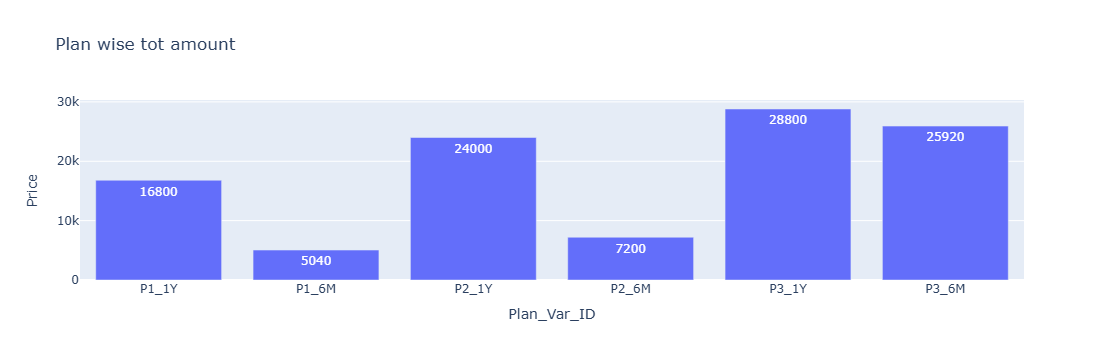

In [152]:
fig = px.bar(data_frame=q6,x='Plan_Var_ID',y='Price',text='Price',
             title = 'Plan wise tot amount')
fig.show()
            
             
             

# 8) Find count of each payment mode, represent it on donut chart

In [155]:
q8 = orders['Payment_mode'].value_counts().reset_index()
q8

,Payment_mode,count
0,Net Banking,29
1,Debit Card,27
2,UPI,24
3,Credit_Card,24
4,COD,23


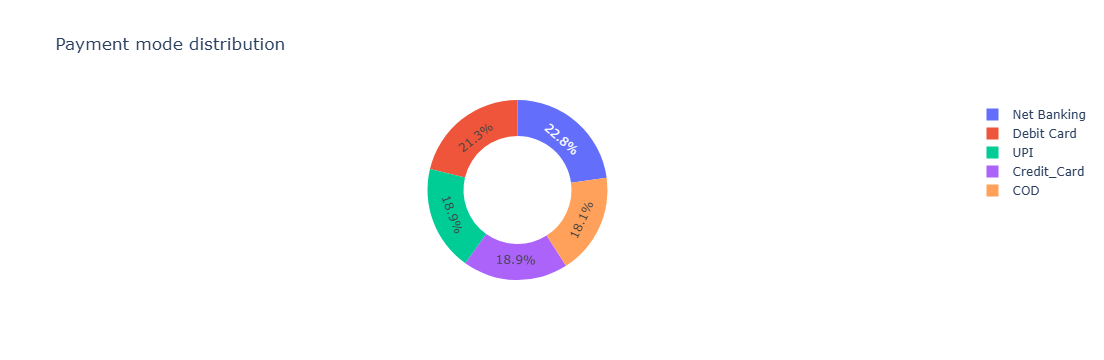

In [165]:
fig = px.pie(data_frame=q8,names='Payment_mode',values='count',hole=0.6,
             title = 'Payment mode distribution' )
fig.show()

In [167]:
#7) City wise find total amount
cb_od= pd.merge(cb,orders,on='Cust_ID')
cb_od.head()

,Cust_ID,City,Age,Age_range,Order_id,Amount,Payment_mode
0,CUS_121,Noida,30,"(27, 31]",ORD_83,3336.69,UPI
1,CUS_127,Delhi,24,"(23, 27]",ORD_172,6427.90,Credit_Card
2,CUS_129,Mumbai,20,"(19, 23]",ORD_97,8653.62,UPI
3,CUS_135,Kolkata,35,"(31, 35]",ORD_87,2551.37,Credit_Card
4,CUS_139,Noida,34,"(31, 35]",ORD_127,3290.14,UPI


In [169]:
q7 = cb_od.groupby('City')['Amount'].count().reset_index()
q7

,City,Amount
0,Chennai,18
1,Delhi,30
2,Kolkata,22
3,Mumbai,23
4,Noida,34


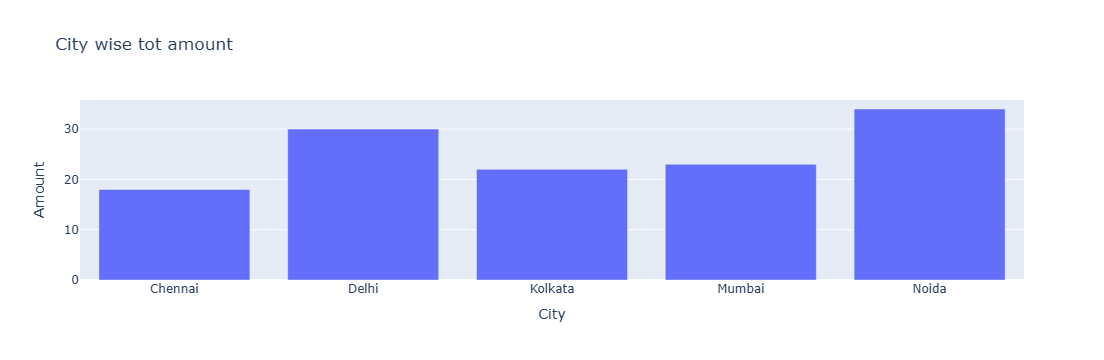

In [171]:
fig = px.bar(data_frame=q7,x='City',y='Amount',
             title = 'City wise tot amount')
fig.show()

In [ ]:
# Represent Payment mode wise sum of amount on a strip plot


## funnel analysis

In [178]:
z1 = ca.groupby(['Cust_ID','Activity'])['Activity'].count().reset_index(name= 'count')
z1

,Cust_ID,Activity,count
0,CUS_121,Add_to_Cart,1
1,CUS_121,Browse,8
2,CUS_121,Checkout,1
3,CUS_121,Sign_Up,1
4,CUS_122,Browse,10
...,...,...,...
1628,CUS_798,Browse,10
1629,CUS_798,Sign_Up,1
1630,CUS_799,Browse,10
1631,CUS_800,Browse,12


In [182]:
funnel =z1['Activity'].value_counts().reset_index()
funnel

,Activity,count
0,Browse,681
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


In [186]:
funnel['prev_count'] = np.where(funnel['Activity']=='Return/Refund',
                                funnel['count'].shift(2),funnel['count'].shift(1))
funnel

,Activity,count,prev_count
0,Browse,681,NaN
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,127.0


In [234]:
funnel['Conversion%']=round((funnel['count']/funnel['prev_count'])*100,2)
funnel = funnel.fillna(0)
funnel

,Activity,count,prev_count,Conversion%,Avg_DayDiff
0,Browse,681,0.0,inf,0.00
1,Sign_Up,478,681.0,70.19,2.52
2,Add_to_Cart,287,478.0,60.04,0.86
3,Checkout,127,287.0,44.25,14.43
4,Review,40,127.0,31.50,2.62
5,Return/Refund,20,127.0,15.75,3.40


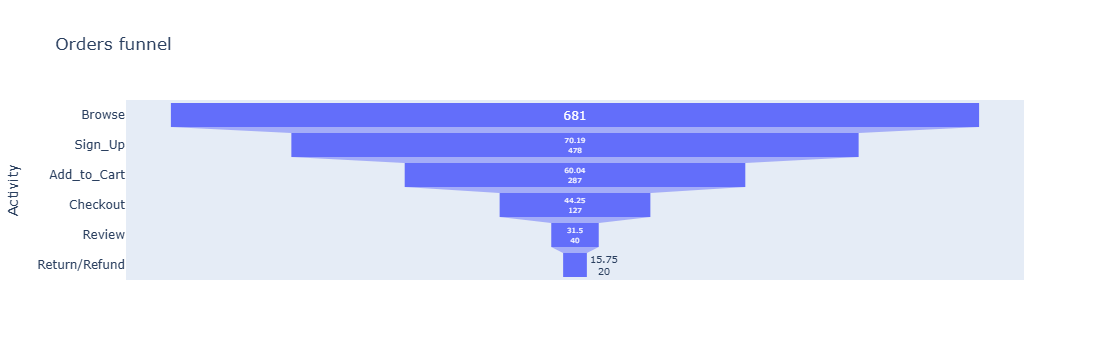

In [236]:
fig= px.funnel(data_frame=funnel,y='Activity',x='count',text='Conversion%',
               hover_data='count',title='Orders funnel',height = 500)
fig.show()               
               

In [202]:
#2) Find Customer wise count of days to transition from one stage of funnel to the next stage
ca.head(20)

,Cust_ID,Activity,Date
0,CUS_121,Sign_Up,2024-04-24
1,CUS_121,Browse,2024-04-27
2,CUS_121,Add_to_Cart,2024-04-27
3,CUS_121,Browse,2024-04-29
4,CUS_121,Browse,2024-04-30
5,CUS_121,Browse,2024-05-04
6,CUS_121,Checkout,2024-05-05
7,CUS_121,Browse,2024-05-07
8,CUS_121,Browse,2024-05-09
9,CUS_121,Browse,2024-05-10


In [204]:
pt1 = pd.pivot_table(data = ca , index = 'Cust_ID',columns = 'Activity',values='Date',aggfunc='min')
pt1.head(10)

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up
Cust_ID,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21


In [206]:
pt1['DD_Signup_2Browse']= abs((pt1['Browse']-pt1['Sign_Up'])).dt.days
pt1['DD_Addtocart_2Browse']=(pt1['Add_to_Cart']-pt1['Browse']).dt.days
pt1['DD_Checkout_2Add2cart']=(pt1['Checkout']-pt1['Add_to_Cart']).dt.days
pt1['DD_Review_2Checkout']= (pt1['Review']-pt1['Checkout']).dt.days
pt1['DD_Return/Refund_2Checkout']= (pt1['Return/Refund']-pt1['Checkout']).dt.days
pt1.head(10)
                                 

                             

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,DD_Signup_2Browse,DD_Addtocart_2Browse,DD_Checkout_2Add2cart,DD_Review_2Checkout,DD_Return/Refund_2Checkout
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,3.0,0.0,8.0,NaN,NaN
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05,1.0,0.0,NaN,NaN,NaN
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15,2.0,NaN,NaN,NaN,NaN
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27,1.0,NaN,NaN,NaN,NaN
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26,2.0,0.0,19.0,NaN,NaN
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21,1.0,0.0,11.0,NaN,NaN


In [208]:
pt2 =pt1.iloc[:,-5:]
pt2.head()

Activity,DD_Signup_2Browse,DD_Addtocart_2Browse,DD_Checkout_2Add2cart,DD_Review_2Checkout,DD_Return/Refund_2Checkout
Cust_ID,,,,,
CUS_121,3.0,0.0,8.0,NaN,NaN
CUS_122,NaN,NaN,NaN,NaN,NaN
CUS_123,NaN,NaN,NaN,NaN,NaN
CUS_124,1.0,0.0,NaN,NaN,NaN
CUS_125,2.0,NaN,NaN,NaN,NaN


In [220]:
#3) Find Avg_Days to transition from one Funnel stage to the next stage.
avg_dd = np.round(pt2.mean().values,2)
avg_dd

array([ 2.52,  0.86, 14.43,  2.62,  3.4 ])

In [222]:
avg_dd= [0] + list(avg_dd)
avg_dd

[0, 2.52, 0.86, 14.43, 2.62, 3.4]

In [224]:
funnel

,Activity,count,prev_count,Conversion%
0,Browse,681,0.0,inf
1,Sign_Up,478,681.0,70.190896
2,Add_to_Cart,287,478.0,60.041841
3,Checkout,127,287.0,44.250871
4,Review,40,127.0,31.496063
5,Return/Refund,20,127.0,15.748031


In [226]:
funnel['Avg_DayDiff']=avg_dd
funnel

,Activity,count,prev_count,Conversion%,Avg_DayDiff
0,Browse,681,0.0,inf,0.00
1,Sign_Up,478,681.0,70.190896,2.52
2,Add_to_Cart,287,478.0,60.041841,0.86
3,Checkout,127,287.0,44.250871,14.43
4,Review,40,127.0,31.496063,2.62
5,Return/Refund,20,127.0,15.748031,3.40


In [246]:
funnel['Conversion%']= funnel['Conversion%'].apply(lambda x :str(x) + '%')
funnel

,Activity,count,prev_count,Conversion%,Avg_DayDiff
0,Browse,681,0.0,inf%,0.00
1,Sign_Up,478,681.0,70.19%,2.52
2,Add_to_Cart,287,478.0,60.04%,0.86
3,Checkout,127,287.0,44.25%,14.43
4,Review,40,127.0,31.5%,2.62
5,Return/Refund,20,127.0,15.75%,3.40


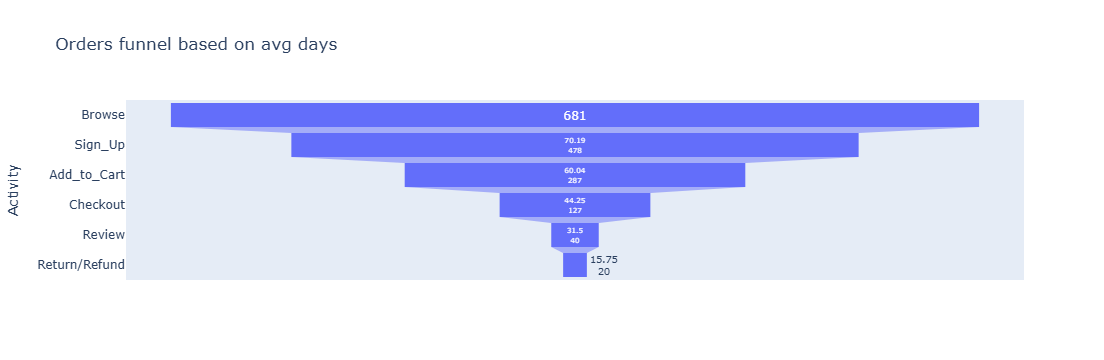

In [242]:
fig= px.funnel(data_frame=funnel,y='Activity',x='count',text='Conversion%',
               hover_data='Avg_DayDiff',title='Orders funnel based on avg days',height = 500)
fig.show()               
            